<a href="https://colab.research.google.com/github/auyashas/fake-job-posting-analyzer/blob/main/fakeJobPostAnalyzer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Dataset Identification

**Project Title:** Machine Learning Based Detection of Fraudulent Job Postings

**Dataset Name:** Real or Fake Job Posting Prediction (Employment Scam Aegean Dataset — EMSCAD)

**Dataset Source:** [Kaggle — Real or Fake Job Posting Prediction](https://www.kaggle.com/datasets/shivamb/real-or-fake-fake-jobposting-prediction)

**Dataset Size:** 17,880 job postings and 18 columns.

**Target Variable:** `fraudulent`

- `0` — Legitimate job posting
- `1` — Fraudulent job posting

**Problem Type:** Supervised binary classification.

**Data Type:** A combination of textual, categorical, binary, and identifier data.

**Dataset Description:** The dataset contains job advertisements with information such as job titles, descriptions, company profiles, qualifications, benefits, employment types, and other job-related attributes. It can be used to develop machine learning models that classify job postings as legitimate or fraudulent.

# 2. Dataset Metadata


In [1]:
import pandas as pd
metadata = [
    ("job_id", "Identifier", "Unique identifier for a job posting"),
    ("title", "Text", "Title of the advertised job"),
    ("location", "Text/Categorical", "Geographical location of the job"),
    ("department", "Categorical", "Department offering the job"),
    ("salary_range", "Text", "Advertised salary range"),
    ("company_profile", "Text", "Information about the company"),
    ("description", "Text", "Description of the job and responsibilities"),
    ("requirements", "Text", "Required skills and qualifications"),
    ("benefits", "Text", "Benefits offered to employees"),
    ("telecommuting", "Binary", "Whether remote work is allowed"),
    ("has_company_logo", "Binary", "Whether a company logo is present"),
    ("has_questions", "Binary", "Whether screening questions are included"),
    ("employment_type", "Categorical", "Type of employment"),
    ("required_experience", "Categorical", "Required experience level"),
    ("required_education", "Categorical", "Required education level"),
    ("industry", "Categorical", "Industry associated with the job"),
    ("function", "Categorical", "Job function or occupational area"),
    ("fraudulent", "Target/Binary", "0 = legitimate, 1 = fraudulent"),
]

metadata_df = pd.DataFrame(
    metadata,
    columns=["Column", "Data Type", "Description"]
)

display(metadata_df)

,Column,Data Type,Description
0,job_id,Identifier,Unique identifier for a job posting
1,title,Text,Title of the advertised job
2,location,Text/Categorical,Geographical location of the job
3,department,Categorical,Department offering the job
4,salary_range,Text,Advertised salary range
5,company_profile,Text,Information about the company
6,description,Text,Description of the job and responsibilities
7,requirements,Text,Required skills and qualifications
8,benefits,Text,Benefits offered to employees
9,telecommuting,Binary,Whether remote work is allowed


# 3. Problem Statement

Online job platforms can contain fraudulent job advertisements intended to mislead job seekers. Identifying such advertisements manually can be time-consuming and difficult because legitimate and fraudulent postings may share similar characteristics.

This project aims to develop a machine learning-based classification system that analyzes textual and structured information from job advertisements to predict whether a posting is legitimate or fraudulent.


# 4. Project Objectives

1. Explore the dataset to understand its structure, feature distributions, missing values, and class imbalance.
2. Identify characteristics that may help distinguish legitimate job postings from fraudulent ones.
3. Develop a preprocessing pipeline suitable for textual and structured job advertisement data.
4. Shortlist appropriate machine learning algorithms, including ensemble learning methods.
5. Evaluate candidate models using suitable classification metrics, particularly precision, recall, F1-score, and the confusion matrix.
6. Identify a suitable model for fraudulent job posting detection based on experimental results.

# 5. Dataset Loading

The dataset is loaded into a Pandas DataFrame for further inspection and exploratory data analysis. Pandas is used to read and manipulate the CSV data.

In [2]:
import gdown

file_id = "1E7gkG9H6jj3hhmSaE4NxQz9bPL-gz_T5"
url = f"https://drive.google.com/uc?id={file_id}"

output = "/content/fake_job_postings.csv"
gdown.download(url, output, quiet=False)

df = pd.read_csv(output, encoding="utf-8")

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)


Downloading...
From: https://drive.google.com/uc?id=1E7gkG9H6jj3hhmSaE4NxQz9bPL-gz_T5
To: /content/fake_job_postings.csv
100%|██████████| 50.1M/50.1M [00:00<00:00, 112MB/s]


Dataset loaded successfully.
Dataset shape: (17880, 18)


# 6. Initial Dataset Inspection

Initial inspection is performed to understand the structure, dimensions, data types, missing values, and duplicate records in the dataset before conducting detailed exploratory data analysis.

In [3]:
# Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDataset information:")
df.info()

# First five records
print("\nFirst five records:")
display(df.head())

# Missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# Duplicate records
print("\nNumber of duplicate rows:", df.duplicated().sum())

Number of rows: 17880
Number of columns: 18

Column names:
['job_id', 'title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   job_id               17880 non-null  int64 
 1   title                17880 non-null  object
 2   location             17534 non-null  object
 3   department           6333 non-null   object
 4   salary_range         2868 non-null   object
 5   company_profile      14572 non-null  object
 6   description          17879 non-null  object
 7   requirements         15184 non-null  object
 8   benefits             10668 non-null

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0



Missing values per column:
job_id                     0
title                      0
location                 346
department             11547
salary_range           15012
company_profile         3308
description                1
requirements            2696
benefits                7212
telecommuting              0
has_company_logo           0
has_questions              0
employment_type         3471
required_experience     7050
required_education      8105
industry                4903
function                6455
fraudulent                 0
dtype: int64

Number of duplicate rows: 0


# 7. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the characteristics of the dataset, identify patterns, examine missing values, and investigate differences between legitimate and fraudulent job postings. Graphs and summary statistics are used to identify patterns that may be useful for machine learning.

## 7.1 Target Variable Distribution

The target variable `fraudulent` indicates whether a job posting is legitimate or fraudulent. The class distribution is examined to understand the balance between the two categories.

Class counts:
fraudulent
0    17014
1      866
Name: count, dtype: int64

Class percentages:
fraudulent
0    95.16
1     4.84
Name: proportion, dtype: float64


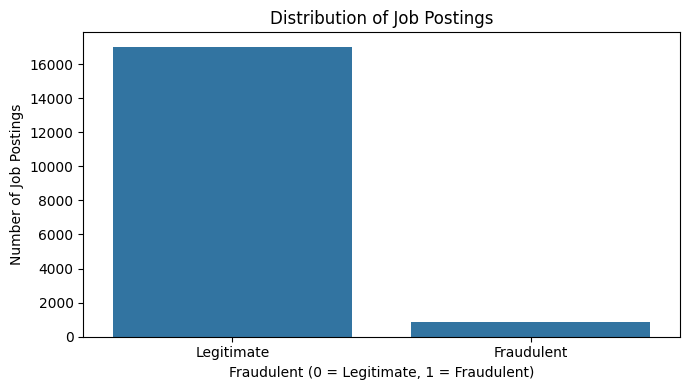

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

target_counts = df["fraudulent"].value_counts().sort_index()

print("Class counts:")
print(target_counts)

print("\nClass percentages:")
print(
    (df["fraudulent"].value_counts(normalize=True) * 100).round(2)
)

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="fraudulent")

plt.title("Distribution of Job Postings")
plt.xlabel("Fraudulent (0 = Legitimate, 1 = Fraudulent)")
plt.ylabel("Number of Job Postings")
plt.xticks([0, 1], ["Legitimate", "Fraudulent"])
plt.tight_layout()
plt.show()

**Observation:** The dataset contains 17,014 legitimate job postings (95.16%) and 866 fraudulent job postings (4.84%). This indicates a substantial class imbalance. Therefore, accuracy alone may not adequately represent model performance, and precision, recall, F1-score, and the confusion matrix should be considered during evaluation.

## 7.2 Missing-Value Analysis

Missing values are examined to identify columns with incomplete information. Understanding the extent of missing data helps determine suitable preprocessing methods.

,Missing Count,Missing Percentage
salary_range,15012,83.96
department,11547,64.58
required_education,8105,45.33
benefits,7212,40.34
required_experience,7050,39.43
function,6455,36.10
industry,4903,27.42
employment_type,3471,19.41
company_profile,3308,18.50
requirements,2696,15.08


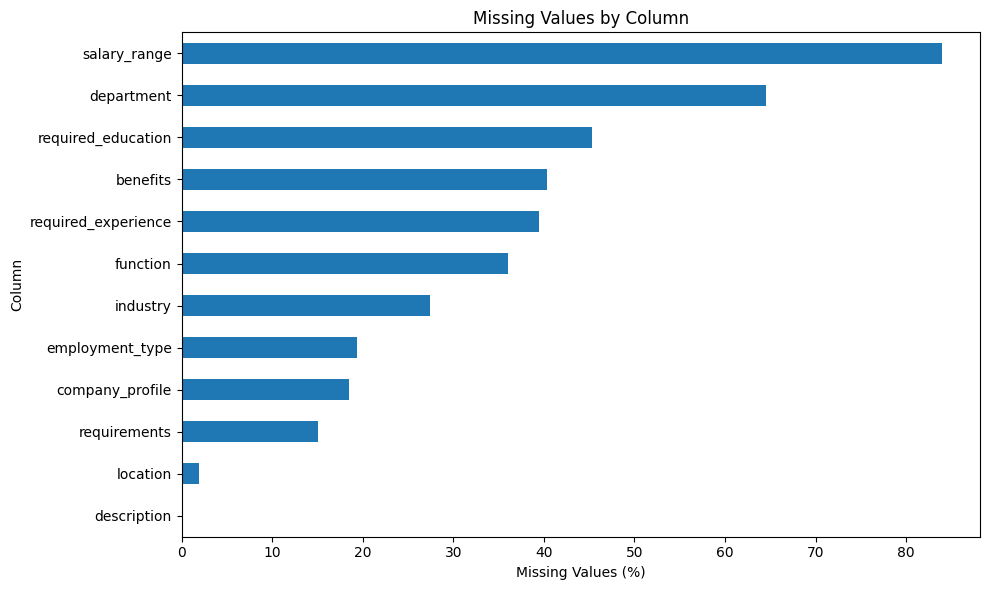

In [5]:
missing_count = df.isnull().sum()

missing_df = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": (
        missing_count / len(df) * 100
    ).round(2)
})

missing_df = missing_df[
    missing_df["Missing Count"] > 0
].sort_values("Missing Percentage", ascending=False)

display(missing_df)

plt.figure(figsize=(10, 6))

missing_df["Missing Percentage"].sort_values().plot(
    kind="barh"
)

plt.title("Missing Values by Column")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

**Observation:** The missing-value analysis shows that `salary_range` has the highest proportion of missing values (83.96%), followed by `department` (64.58%). Other features, including `required_education` (45.33%) and `benefits` (40.34%), also contain substantial missing data. The `description` column has only one missing value (0.01%). These findings indicate that missing values must be handled carefully during preprocessing rather than removing all incomplete records.

## 7.3 Categorical Feature Analysis

The distributions of selected categorical features are examined to identify the most frequently occurring job types, experience levels, education requirements, industries, and job functions.

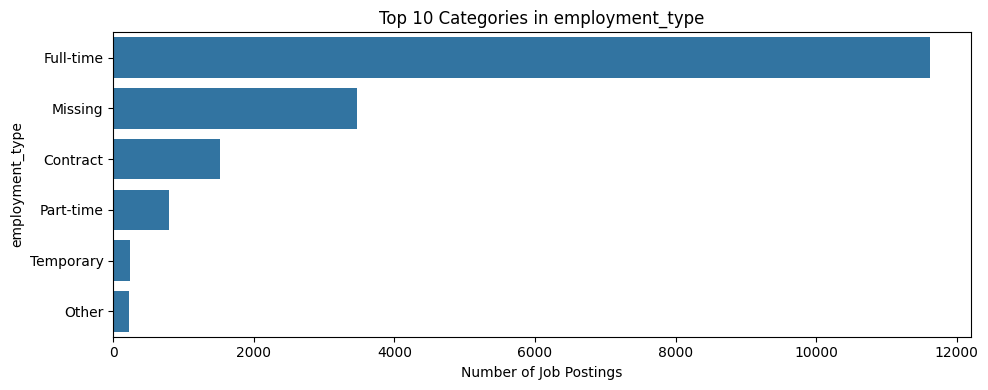

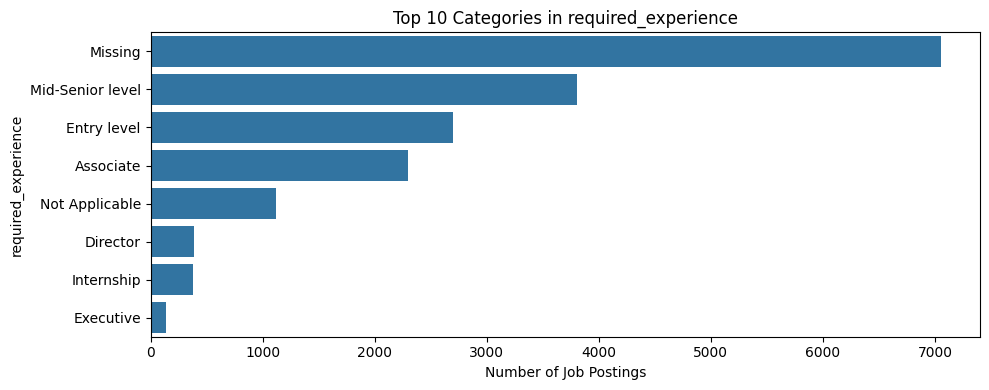

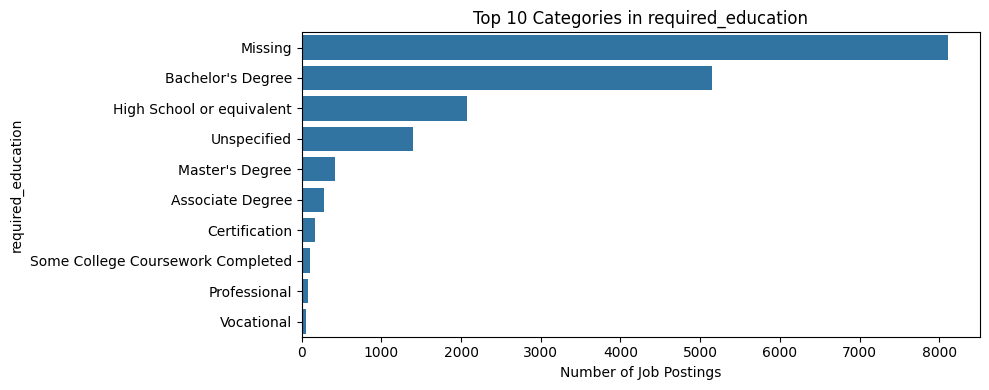

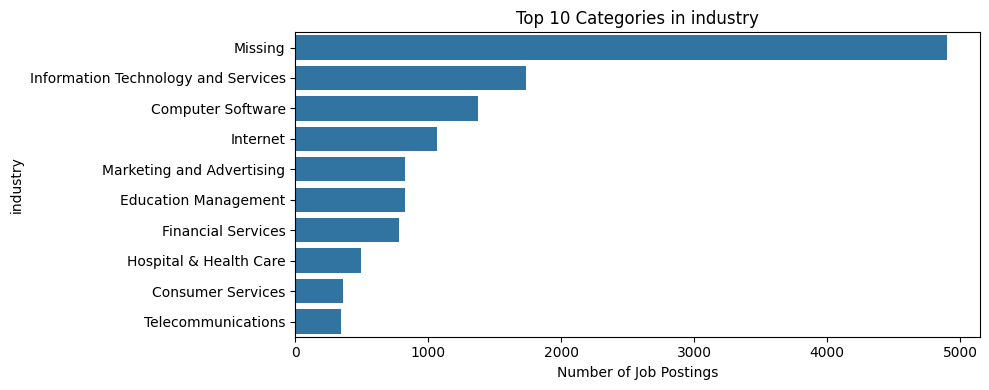

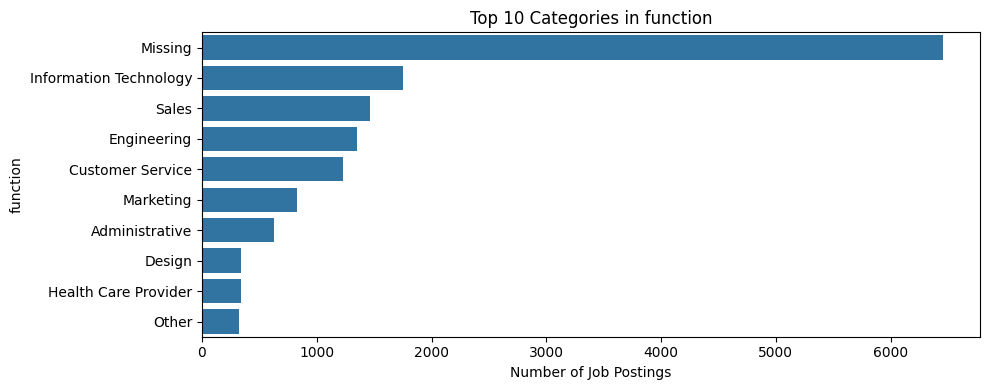

In [6]:
categorical_cols = [
    "employment_type",
    "required_experience",
    "required_education",
    "industry",
    "function"
]

for col in categorical_cols:
    plt.figure(figsize=(10, 4))

    values = (
        df[col]
        .fillna("Missing")
        .value_counts()
        .head(10)
    )

    sns.barplot(x=values.values, y=values.index)

    plt.title(f"Top 10 Categories in {col}")
    plt.xlabel("Number of Job Postings")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

**Observation:** The categorical distributions show how job advertisements are represented across employment types, experience levels, education requirements, industries, and job functions. These features may provide useful information for classification. However, the current charts show category frequencies rather than fraudulent posting rates within each category. Missing categorical values will need to be handled, and categorical features will require appropriate encoding before model training.

## 7.4 Text-Length Analysis

Text-length analysis is used to examine the lengths of job titles, company profiles, descriptions, requirements, and benefits. Comparing text lengths across legitimate and fraudulent postings may reveal useful patterns in the advertisements.

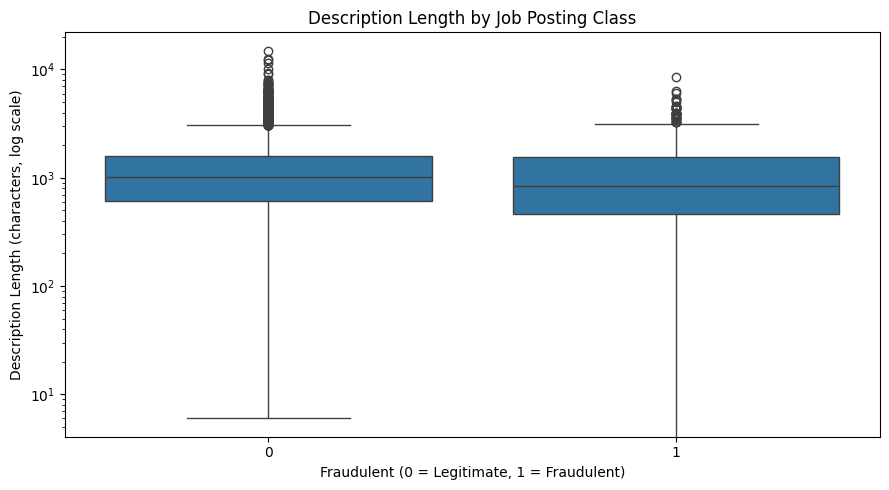

Average text length by class:


,title_length,company_profile_length,description_length,requirements_length,benefits_length
fraudulent,,,,,
0,28.42,640.75,1221.22,597.47,208.73
1,30.67,230.89,1154.83,446.05,212.20


In [7]:
text_cols = [
    "title",
    "company_profile",
    "description",
    "requirements",
    "benefits"
]

text_lengths = pd.DataFrame(index=df.index)

for col in text_cols:
    text_lengths[f"{col}_length"] = (
        df[col].fillna("").str.len()
    )

text_lengths["fraudulent"] = df["fraudulent"]

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=text_lengths,
    x="fraudulent",
    y="description_length"
)

plt.yscale("log")
plt.title("Description Length by Job Posting Class")
plt.xlabel("Fraudulent (0 = Legitimate, 1 = Fraudulent)")
plt.ylabel("Description Length (characters, log scale)")
plt.tight_layout()
plt.show()

print("Average text length by class:")
display(
    text_lengths.groupby("fraudulent")[
        [f"{col}_length" for col in text_cols]
    ].mean().round(2)
)


**Observation:** The boxplot shows that legitimate job postings have a slightly higher median description length than fraudulent postings. The average description length is 1,238.69 characters for legitimate postings and 1,162.70 characters for fraudulent postings. The average company profile and requirements lengths are also higher for legitimate postings, while the average title and benefits lengths are slightly higher for fraudulent postings. These differences may provide useful information for classification; however, text length alone cannot determine whether a job posting is fraudulent.

## 7.5 Binary Feature Analysis

The relationship between selected binary features and fraudulent job postings is examined. These features include telecommuting availability, company logo presence, and the inclusion of screening questions.

In [8]:
binary_cols = [
    "telecommuting",
    "has_company_logo",
    "has_questions"
]

for col in binary_cols:
    summary = (
        df.groupby(col, dropna=False)["fraudulent"]
        .agg(["count", "mean"])
        .rename(columns={
            "count": "Number of Postings",
            "mean": "Fraudulent Rate"
        })
    )

    summary["Fraudulent Rate (%)"] = (
        summary["Fraudulent Rate"] * 100
    ).round(2)

    print(f"\nAnalysis of {col}:")
    display(summary)


Analysis of telecommuting:


,Number of Postings,Fraudulent Rate,Fraudulent Rate (%)
telecommuting,,,
0,17113,0.046865,4.69
1,767,0.083442,8.34



Analysis of has_company_logo:


,Number of Postings,Fraudulent Rate,Fraudulent Rate (%)
has_company_logo,,,
0,3660,0.159290,15.93
1,14220,0.019902,1.99



Analysis of has_questions:


,Number of Postings,Fraudulent Rate,Fraudulent Rate (%)
has_questions,,,
0,9088,0.067782,6.78
1,8792,0.028435,2.84


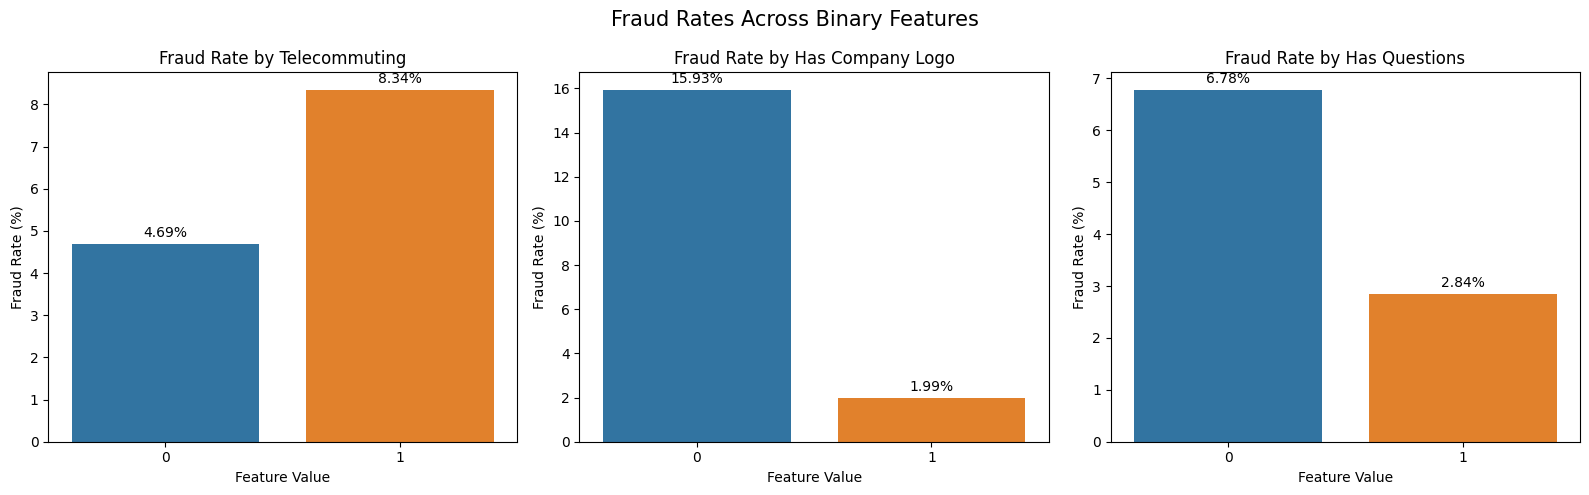

In [9]:
binary_features = [
    "telecommuting",
    "has_company_logo",
    "has_questions"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, feature in zip(axes, binary_features):
    fraud_rates = (
        df.groupby(feature, dropna=False)["fraudulent"]
        .mean()
        .mul(100)
        .reset_index(name="Fraud Rate (%)")
    )

    fraud_rates[feature] = fraud_rates[feature].astype(str)

    sns.barplot(
        data=fraud_rates,
        x=feature,
        y="Fraud Rate (%)",
        hue=feature,
        legend=False,
        ax=ax
    )

    ax.set_title(f"Fraud Rate by {feature.replace('_', ' ').title()}")
    ax.set_xlabel("Feature Value")
    ax.set_ylabel("Fraud Rate (%)")

    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.suptitle("Fraud Rates Across Binary Features", fontsize=15)
plt.tight_layout()
plt.show()


**Observation:** The fraudulent posting rate is higher among postings without a company logo (15.93%) than among those with a logo (1.99%). Postings without screening questions also show a higher fraudulent rate (6.78%) than those with screening questions (2.84%). Additionally, postings allowing telecommuting have a higher fraudulent rate (8.34%) than postings that do not (4.69%). These patterns indicate potentially useful associations for classification, but they do not establish causation.

# 8. Proposed Preprocessing Pipeline

The dataset contains textual, categorical, binary, and identifier features. A preprocessing pipeline will be designed to transform these features into a suitable representation for machine learning.

1. **Data validation:** Verify data types, missing values, duplicates, and inconsistent values.
2. **Identifier handling:** Exclude `job_id` from the predictive features because it is an identifier rather than meaningful job content.
3. **Text preprocessing:** Handle missing text fields and combine selected textual columns for TF-IDF vectorization.
4. **Categorical preprocessing:** Handle missing categorical values and apply one-hot encoding.
5. **Binary preprocessing:** Convert binary values to consistent numerical representations where necessary.
6. **Train-test split:** Split the data into training and testing sets using stratification to preserve class proportions.
7. **Class imbalance:** Evaluate class-weighted learning methods where supported.
8. **Leakage prevention:** Fit preprocessing transformations on the training data only, using pipelines where appropriate.

The preprocessing decisions will be validated during model implementation.

# 9. Model Selection

Six machine learning algorithms have been shortlisted for the fraudulent job posting classification task. The selected models represent different classification approaches, including linear, probabilistic, tree-based, and ensemble methods.

1. **Logistic Regression:** A baseline classifier suitable for high-dimensional TF-IDF features.
2. **Multinomial Naïve Bayes:** A probabilistic classifier commonly used for text classification.
3. **Decision Tree:** A tree-based classifier capable of modelling non-linear relationships.
4. **Random Forest:** An ensemble method that combines predictions from multiple decision trees.
5. **AdaBoost:** An ensemble method that combines sequentially trained weak learners.
6. **K-Nearest Neighbors (KNN):** An instance-based classifier included for comparison, although high-dimensional sparse text features may make it computationally less suitable.

Random Forest and AdaBoost satisfy the requirement to shortlist at least two ensemble models.

Model performance will be compared using precision, recall, F1-score, and confusion matrices, with particular attention to detecting fraudulent postings.

# Phase 2: Model Implementation and Evaluation

## 10. Data Preparation for Model Training

In this phase, the dataset is prepared for supervised machine learning. The target variable is separated from the input features, the job identifier is excluded, and the data is divided into training and testing sets using stratified sampling. This ensures that the class distribution is approximately preserved in both sets.

In [10]:
from sklearn.model_selection import train_test_split

# Work with a copy of the original dataset
model_df = df.copy()

# Separate target variable from input features
y = model_df["fraudulent"].astype(int)

# Exclude target and job identifier from input features
X = model_df.drop(columns=["fraudulent", "job_id"])

# Identify text columns
text_columns = [
    "title",
    "company_profile",
    "description",
    "requirements",
    "benefits"
]

# Combine text fields into a single text feature
X["combined_text"] = (
    X[text_columns]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
)

# Remove the original text columns after combining them
X = X.drop(columns=text_columns)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data preparation completed successfully.")
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

print("\nInput features:")
print(X_train.columns.tolist())

Data preparation completed successfully.
Training features: (14304, 12)
Testing features: (3576, 12)

Training target distribution:
fraudulent
0    13611
1      693
Name: count, dtype: int64

Testing target distribution:
fraudulent
0    3403
1     173
Name: count, dtype: int64

Input features:
['location', 'department', 'salary_range', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'combined_text']


## 11. Preprocessing Pipeline

A preprocessing pipeline is developed to transform textual and structured features into numerical representations suitable for machine learning. TF-IDF is applied to the combined job-posting text, while categorical features are imputed and one-hot encoded. Binary features are imputed and retained as numerical variables. Using a pipeline ensures that preprocessing is fitted on the training data and then applied consistently to the test data.

In [11]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Identify structured feature columns
binary_columns = [
    "telecommuting",
    "has_company_logo",
    "has_questions"
]

categorical_columns = [
    "location",
    "department",
    "salary_range",
    "employment_type",
    "required_experience",
    "required_education",
    "industry",
    "function"
]

# Preprocessing for categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Preprocessing for binary features
binary_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

# Combine text and structured preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "text",
            TfidfVectorizer(
                max_features=20000,
                ngram_range=(1, 2),
                sublinear_tf=True,
                stop_words="english",
                dtype="float32"
            ),
            "combined_text"
        ),
        ("categorical", categorical_pipeline, categorical_columns),
        ("binary", binary_pipeline, binary_columns)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created successfully.")


Preprocessing pipeline created successfully.


In [12]:

# Test preprocessing on a small sample first
X_sample = X_train.iloc[:500]

X_sample_transformed = preprocessor.fit_transform(X_sample)

print("Original sample shape:", X_sample.shape)
print("Transformed sample shape:", X_sample_transformed.shape)
print("Sparse matrix:", hasattr(X_sample_transformed, "tocsr"))


/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:2043: UserWarning: Only (<class 'numpy.float64'>, <class 'numpy.float32'>, <class 'numpy.float16'>) 'dtype' should be used. float32 'dtype' will be converted to np.float64.
  warnings.warn(


Original sample shape: (500, 12)
Transformed sample shape: (500, 20608)
Sparse matrix: True


## 12. Model Implementation

Six supervised machine learning classifiers are selected for implementation: Logistic Regression, Multinomial Naïve Bayes, Decision Tree, K-Nearest Neighbors, Random Forest, and AdaBoost. Random Forest and AdaBoost are ensemble learning methods. Each model will be trained using the same preprocessing approach and training data to enable a fair comparison.

In [13]:

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
import time

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),

    "Multinomial Naive Bayes": MultinomialNB(),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5,
        n_jobs=-1
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "AdaBoost": AdaBoostClassifier(
        n_estimators=100,
        random_state=42
    )
}

trained_models = {}
training_times = {}

for name, model in models.items():
    print(f"Training {name}...")
    start = time.time()

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline
    training_times[name] = round(time.time() - start, 2)

    print(f"Completed in {training_times[name]} seconds.")

print("\nAll six models have been trained.")


Training Logistic Regression...


/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:2043: UserWarning: Only (<class 'numpy.float64'>, <class 'numpy.float32'>, <class 'numpy.float16'>) 'dtype' should be used. float32 'dtype' will be converted to np.float64.
  warnings.warn(


Completed in 26.68 seconds.
Training Multinomial Naive Bayes...


/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:2043: UserWarning: Only (<class 'numpy.float64'>, <class 'numpy.float32'>, <class 'numpy.float16'>) 'dtype' should be used. float32 'dtype' will be converted to np.float64.
  warnings.warn(


Completed in 17.36 seconds.
Training Decision Tree...


...

Completed in 16.69 seconds.
Training Random Forest...


/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:2043: UserWarning: Only (<class 'numpy.float64'>, <class 'numpy.float32'>, <class 'numpy.float16'>) 'dtype' should be used. float32 'dtype' will be converted to np.float64.
  warnings.warn(


Completed in 29.86 seconds.
Training AdaBoost...


/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:2043: UserWarning: Only (<class 'numpy.float64'>, <class 'numpy.float32'>, <class 'numpy.float16'>) 'dtype' should be used. float32 'dtype' will be converted to np.float64.
  warnings.warn(


Completed in 96.16 seconds.

All six models have been trained.


## 13. Model Evaluation

The trained classifiers are evaluated using the same independent test set. Accuracy, precision, recall, F1-score, ROC-AUC, and average precision are calculated to compare their performance. Since fraudulent job postings are the minority class, particular attention is given to fraudulent-class recall, F1-score, and average precision. These metrics help assess how effectively each model identifies fraudulent postings while accounting for class imbalance.

In [14]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)
import pandas as pd

results = []
predictions = {}
probabilities = {}

for name, pipeline in trained_models.items():
    # Predict labels and fraud probabilities on the test set
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    predictions[name] = y_pred
    probabilities[name] = y_prob

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Fraud Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Fraud Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "Fraud F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Average Precision": average_precision_score(
            y_test, y_prob
        )
    })

results_df = pd.DataFrame(results)

# Display the comparison, sorted by fraudulent-class F1
results_df = results_df.sort_values(
    by="Fraud F1-Score",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

print("\nDetailed classification reports")
for name in trained_models:
    print(f"\n{'=' * 60}")
    print(name)
    print(classification_report(
        y_test,
        predictions[name],
        target_names=["Legitimate", "Fraudulent"],
        zero_division=0
    ))


,Model,Accuracy,Fraud Precision,Fraud Recall,Fraud F1-Score,ROC-AUC,Average Precision
0,Logistic Regression,0.9790,0.7290,0.9017,0.8062,0.9896,0.9351
1,K-Nearest Neighbors,0.9810,0.9070,0.6763,0.7748,0.9401,0.8183
2,Decision Tree,0.9746,0.7228,0.7688,0.7451,0.8769,0.5669
3,Random Forest,0.9793,0.9806,0.5838,0.7319,0.9904,0.9101
4,Multinomial Naive Bayes,0.9695,0.9324,0.3988,0.5587,0.9525,0.7177
5,AdaBoost,0.9634,0.9200,0.2659,0.4126,0.9703,0.7097



Detailed classification reports

Logistic Regression
              precision    recall  f1-score   support

  Legitimate       0.99      0.98      0.99      3403
  Fraudulent       0.73      0.90      0.81       173

    accuracy                           0.98      3576
   macro avg       0.86      0.94      0.90      3576
weighted avg       0.98      0.98      0.98      3576


Multinomial Naive Bayes
              precision    recall  f1-score   support

  Legitimate       0.97      1.00      0.98      3403
  Fraudulent       0.93      0.40      0.56       173

    accuracy                           0.97      3576
   macro avg       0.95      0.70      0.77      3576
weighted avg       0.97      0.97      0.96      3576


Decision Tree
              precision    recall  f1-score   support

  Legitimate       0.99      0.99      0.99      3403
  Fraudulent       0.72      0.77      0.75       173

    accuracy                           0.97      3576
   macro avg       0.86      0.88 

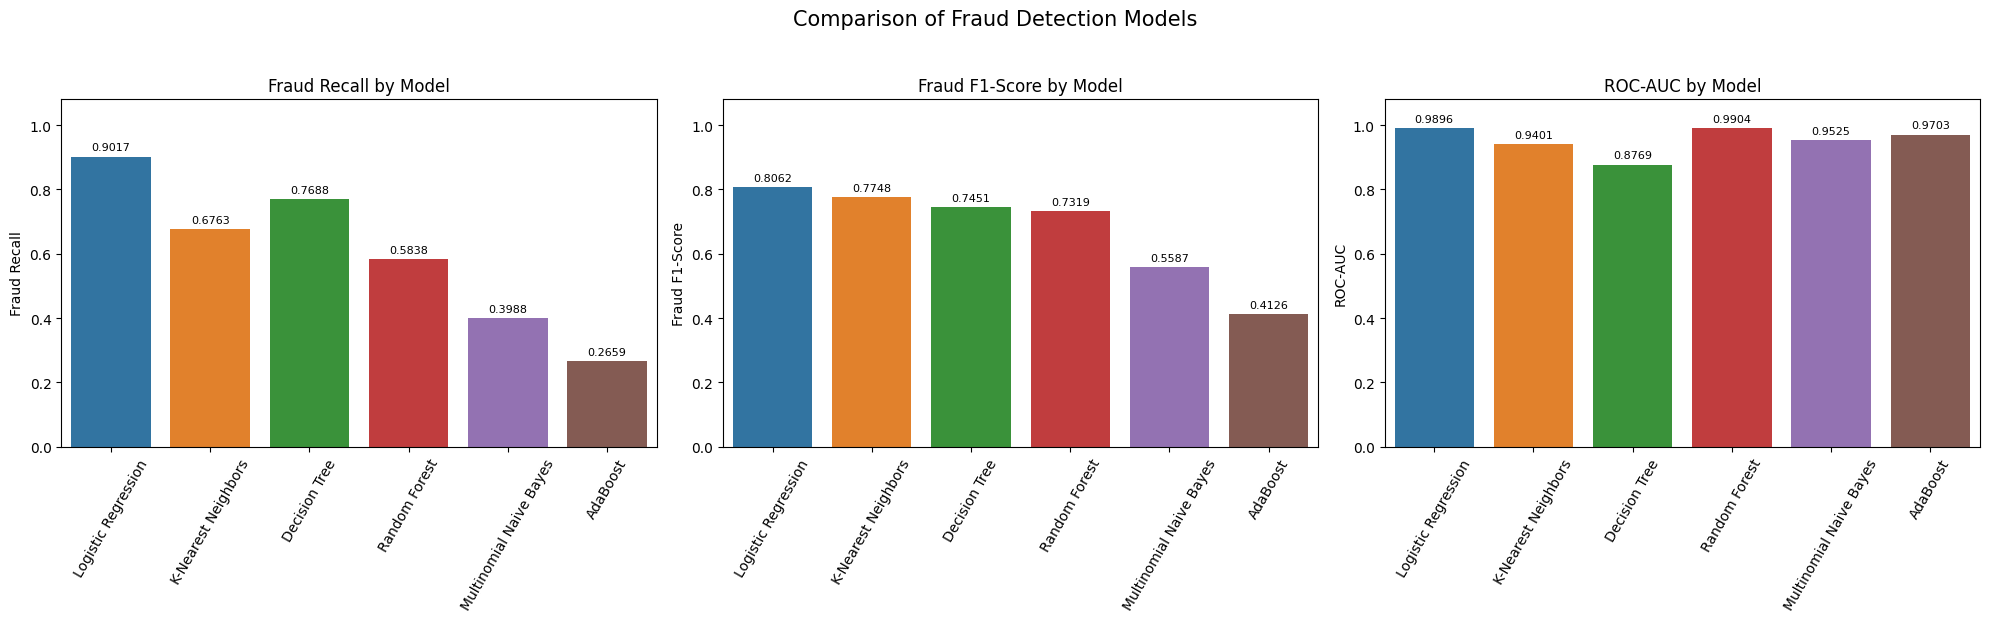

In [15]:
# Select the metrics most useful for comparing fraud detection models
metrics_to_plot = [
    ("Fraud Recall", "Fraud Recall by Model"),
    ("Fraud F1-Score", "Fraud F1-Score by Model"),
    ("ROC-AUC", "ROC-AUC by Model")
]

# Copy the existing evaluation results
plot_df = results_df.copy()

# Create three comparison plots
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, (metric, title) in zip(axes, metrics_to_plot):
    sns.barplot(
        data=plot_df,
        x="Model",
        y=metric,
        hue="Model",
        legend=False,
        ax=ax
    )

    ax.set_title(title, fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1.08)
    ax.tick_params(axis="x", rotation=60)

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.4f",
            padding=3,
            fontsize=8
        )

plt.suptitle(
    "Comparison of Fraud Detection Models",
    fontsize=15,
    y=1.03
)
plt.tight_layout()
plt.show()


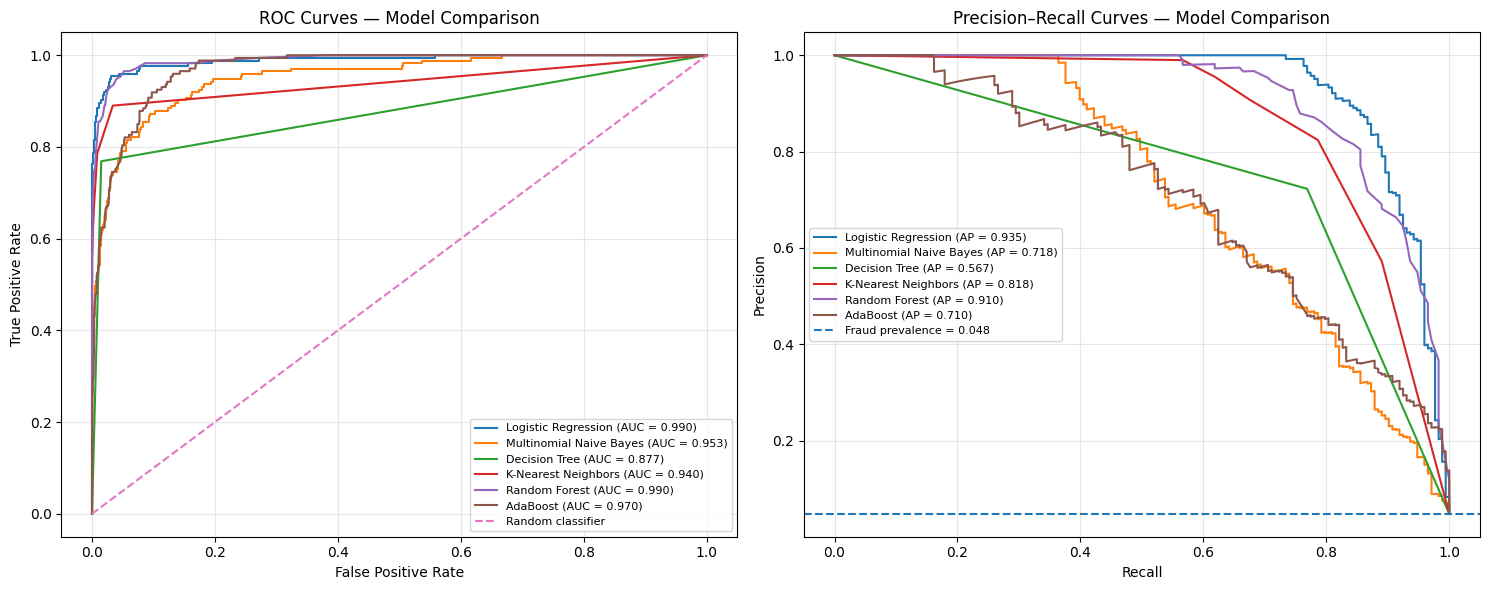

In [16]:

import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. ROC curves
for name, y_prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    axes[0].plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

axes[0].plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random classifier"
)

axes[0].set_title("ROC Curves — Model Comparison")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right", fontsize=8)
axes[0].grid(alpha=0.3)

# 2. Precision–Recall curves
for name, y_prob in probabilities.items():
    precision, recall, _ = precision_recall_curve(
        y_test, y_prob
    )
    avg_precision = average_precision_score(
        y_test, y_prob
    )

    axes[1].plot(
        recall,
        precision,
        label=f"{name} (AP = {avg_precision:.3f})"
    )

# Baseline: proportion of fraudulent cases in the test set
fraud_prevalence = y_test.mean()
axes[1].axhline(
    fraud_prevalence,
    linestyle="--",
    label=f"Fraud prevalence = {fraud_prevalence:.3f}"
)

axes[1].set_title("Precision–Recall Curves — Model Comparison")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="best", fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


**Observation:** Logistic Regression achieved the highest fraudulent-class F1-score (0.8062) and recall (90.17%), making it the strongest candidate for detecting fraudulent job postings among the six evaluated models. K-Nearest Neighbors achieved the highest accuracy (98.10%), while Random Forest achieved the highest ROC-AUC (0.9904) and fraudulent-class precision (98.06%). However, both models missed more fraudulent postings than Logistic Regression at the default classification threshold. Therefore, model selection should consider the trade-off between detecting fraud and avoiding false alarms rather than relying on accuracy alone.

## 14. Confusion Matrix Analysis

Confusion matrices are used to examine the classification results of each model. They show true positives, true negatives, false positives, and false negatives. This analysis helps identify how frequently legitimate postings are incorrectly flagged and how frequently fraudulent postings are missed.

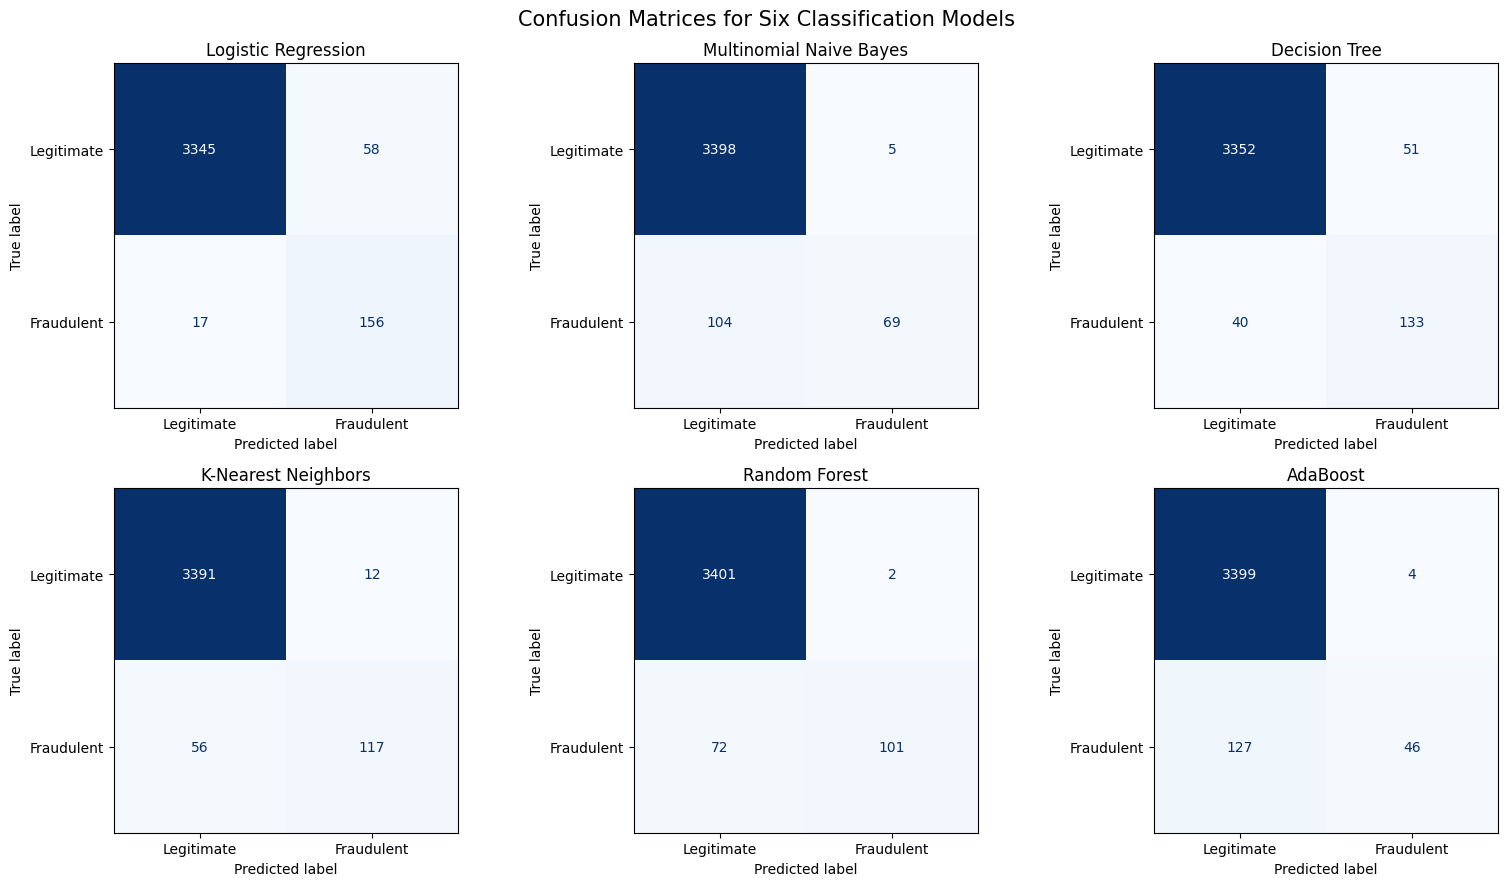

In [17]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Legitimate", "Fraudulent"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(name)

plt.suptitle("Confusion Matrices for Six Classification Models", fontsize=15)
plt.tight_layout()
plt.show()


In [18]:

confusion_results = []

for name, y_pred in predictions.items():
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    confusion_results.append({
        "Model": name,
        "True Negatives": tn,
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp
    })

confusion_df = pd.DataFrame(confusion_results)
display(confusion_df)


,Model,True Negatives,False Positives,False Negatives,True Positives
0,Logistic Regression,3345,58,17,156
1,Multinomial Naive Bayes,3398,5,104,69
2,Decision Tree,3352,51,40,133
3,K-Nearest Neighbors,3391,12,56,117
4,Random Forest,3401,2,72,101
5,AdaBoost,3399,4,127,46


**Observation:** Logistic Regression correctly identified 156 out of 173 fraudulent job postings and missed only 17, achieving the highest fraud recall among the six models. However, it incorrectly classified 58 legitimate postings as fraudulent. Random Forest produced only 2 false positives but missed 72 fraudulent postings. These results highlight the trade-off between detecting fraudulent postings and minimizing false alarms. Considering the project's primary objective of detecting fraudulent job advertisements, Logistic Regression is selected as the leading candidate based on its fraudulent-class recall and F1-score.

## 15. Saving the Selected Model

Logistic Regression is selected as the leading candidate because it achieved the highest fraudulent-class recall and F1-score among the six evaluated models. The complete preprocessing and classification pipeline is saved so it can be reused for predictions in the deployment phase.

In [19]:

import joblib
import os

# Select the best candidate based on current test results
best_model_name = "Logistic Regression"
best_model = trained_models[best_model_name]

# Save the entire pipeline, including preprocessing
model_path = "/content/fraudulent_job_detector.joblib"

joblib.dump(best_model, model_path)

print("Selected model:", best_model_name)
print("Model saved to:", model_path)
print("File size (MB):", round(os.path.getsize(model_path) / (1024 * 1024), 2))


Selected model: Logistic Regression
Model saved to: /content/fraudulent_job_detector.joblib
File size (MB): 1.01


In [20]:

loaded_model = joblib.load(
    "/content/fraudulent_job_detector.joblib"
)

sample_predictions = loaded_model.predict(X_test.iloc[:5])

print("Model loaded successfully.")
print("Sample predictions:", sample_predictions)
print("Actual labels:", y_test.iloc[:5].to_numpy())


Model loaded successfully.
Sample predictions: [0 0 0 0 0]
Actual labels: [0 0 0 0 0]
